In [13]:
import time; T0 = time.time()
import numpy as np, matplotlib.pyplot as plt
from scipy import stats
from mp2lib import (inv_cdf_exponential, inv_cdf_rayleigh, sample_by_inversion,
                    ks_statistic, q_function, cdf_y, pdf_y, rayleigh_moments, generate_samples, running_stats)



from scipy.stats import norm
from scipy.integrate import quad
from math import gamma



SEED = 981253769
rng = np.random.default_rng(SEED)
# one independent generator per step, created once
rng_step = {k: g for k, g in zip(range(1, 9), rng.spawn(8))}
N = 10**5
KS_CRIT = 1.36 / np.sqrt(N)
print(f"N = {N}, 95% KS critical value = {KS_CRIT:.4f}")

ImportError: cannot import name 'rayleigh_moments' from 'mp2lib' (c:\Users\sikan\OneDrive\Desktop\MP2_github\ece3715\mp2\mp2lib.py)

## Step 1: From CDF to Density

**The Four Distributions**

| Distribution | Support | CDF $F(x)$ | pdf $f(x)$ |
|---|---|---|---|
| Uniform on $[0,1]$ | $[0,1]$ | $x$ | $1$ |
| Exponential, rate 1 | $[0,\infty)$ | $1-e^{-x}$ | $e^{-x}$ |
| Standard Gaussian | $(-\infty,\infty)$ | $\Phi(x)=\tfrac12\left[1+\operatorname{erf}\left(x/\sqrt2\right)\right]$ | $\tfrac{1}{\sqrt{2\pi}}\,e^{-x^2/2}$ |
| Rayleigh, scale 1 | $[0,\infty)$ | $1-e^{-x^2/2}$ | $x\,e^{-x^2/2}$ |

Outside its support, each pdf is 0 and each CDF is 0 to the left and 1 to the right.

**Closed Forms**

| | Mean | Median | Variance |
|---|---|---|---|
| Exponential, rate $\lambda$ | $\dfrac{1}{\lambda}$ | $\dfrac{\ln 2}{\lambda}$ | $\dfrac{1}{\lambda^{2}}$ |
| Rayleigh, scale $\sigma$ | $\sigma\sqrt{\dfrac{\pi}{2}}$ | $\sigma\sqrt{2\ln 2}$ | $\dfrac{4-\pi}{2}\,\sigma^{2}$ |

With $\lambda=\sigma=1$:

- Exponential: mean $1$, median $0.6931$, variance $1$.
- Rayleigh: mean $1.2533$, median $1.1774$, variance $0.4292$.

**Explanation**

The exponential density is skewed to the right: its long tail carries rare, large values that pull the mean up to 1, while the median only marks the point with half the probability on each side and stays at $\ln 2\approx0.693$, a ratio of about 1.44. The Gaussian density is symmetric about its center, so the point that splits the probability in half is also the balance point, and the mean and median coincide.

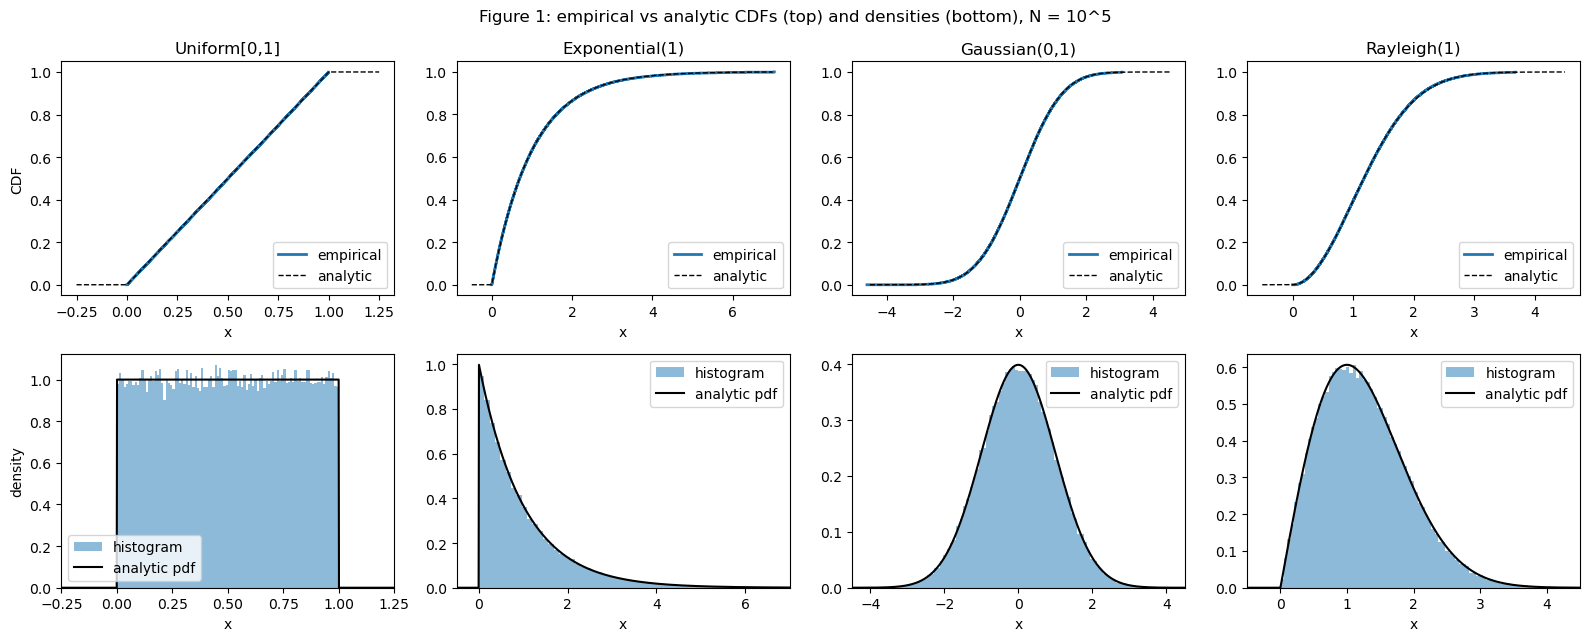

distribution      KS statistic  95% crit   verdict
Uniform[0,1]           0.00228    0.0043   pass
Exponential(1)         0.00205    0.0043   pass
Gaussian(0,1)          0.00237    0.0043   pass
Rayleigh(1)            0.00260    0.0043   pass
                              sample  closed form
Exponential(1)  mean          1.0017       1.0000
Exponential(1)  median        0.6932       0.6931
Exponential(1)  variance      1.0146       1.0000
Rayleigh(1)     mean          1.2525       1.2533
Rayleigh(1)     median        1.1808       1.1774
Rayleigh(1)     variance      0.4283       0.4292


In [10]:
# STEP 1 - From CDF to Density

# Figure 1. Empirical vs Analytic CDF Figures and Histograms
r1 = rng_step[1]
dists = {
 "Uniform[0,1]": dict(draw=lambda n: r1.random(n),            cdf=lambda x: np.clip(x,0,1),
                      pdf=lambda x: ((x>=0)&(x<=1)).astype(float), xs=(-0.25,1.25)),
 "Exponential(1)": dict(draw=lambda n: r1.exponential(1.0, n), cdf=lambda x: np.where(x>0,1-np.exp(-np.maximum(x,0)),0.0),
                      pdf=lambda x: np.where(x>=0,np.exp(-np.maximum(x,0)),0.0), xs=(-0.5,7)),
 "Gaussian(0,1)": dict(draw=lambda n: r1.standard_normal(n), cdf=stats.norm.cdf,
                      pdf=stats.norm.pdf, xs=(-4.5,4.5)),
 "Rayleigh(1)": dict(draw=lambda n: r1.rayleigh(1.0, n),     cdf=lambda x: np.where(x>0,1-np.exp(-np.maximum(x,0)**2/2),0.0),
                      pdf=lambda x: np.where(x>=0,x*np.exp(-x**2/2),0.0), xs=(-0.5,4.5)),
}
samples = {k: d["draw"](N) for k, d in dists.items()}
 
fig, ax = plt.subplots(2, 4, figsize=(16, 6.5))
for j, (k, d) in enumerate(dists.items()):
    s = np.sort(samples[k]); x = np.linspace(*d["xs"], 1000)
    ax[0,j].step(s[::100], np.arange(1, N+1)[::100]/N, where="post", color="C0", lw=2, label="empirical")
    ax[0,j].plot(x, d["cdf"](x), "k--", lw=1, label="analytic")
    ax[0,j].set_title(k); ax[0,j].set_xlabel("x"); ax[0,j].legend(loc="lower right")
    ax[1,j].hist(samples[k], bins=100, density=True, color="C0", alpha=.5, label="histogram")
    ax[1,j].plot(x, d["pdf"](x), "k", lw=1.5, label="analytic pdf")
    ax[1,j].set_xlim(*d["xs"]); ax[1,j].set_xlabel("x"); ax[1,j].legend()
ax[0,0].set_ylabel("CDF"); ax[1,0].set_ylabel("density")
fig.suptitle("Figure 1: empirical vs analytic CDFs (top) and densities (bottom), N = 10^5")
fig.tight_layout(); plt.show()
 
# KS statistic table
print(f"{'distribution':<16}{'KS statistic':>14}{'95% crit':>10}   verdict")
for k, d in dists.items():
    ks = ks_statistic(samples[k], d["cdf"])
    print(f"{k:<16}{ks:>14.5f}{KS_CRIT:>10.4f}   {'pass' if ks < KS_CRIT else 'FAIL'}")
 
# Sample mean, median, variance vs closed form
closed = {"Exponential(1)": (1.0, np.log(2), 1.0),
          "Rayleigh(1)":    (np.sqrt(np.pi/2), np.sqrt(2*np.log(2)), (4-np.pi)/2)}
print(f"{'':<16}{'':<10}{'sample':>10}{'closed form':>13}")
for k, (m, med, v) in closed.items():
    s = samples[k]
    for name, emp, th in [("mean", s.mean(), m), ("median", np.median(s), med), ("variance", s.var(ddof=1), v)]:
        print(f"{k:<16}{name:<10}{emp:>10.4f}{th:>13.4f}")

## Step 2: Build Your Own Generator by Inversion

**Inversion theorem.** Let $U$ be uniform on $[0,1]$, and let $F$ be a continuous, strictly increasing CDF with inverse $F^{-1}$. Then $X=F^{-1}(U)$ has CDF $F$.

*Proof.* Because $F$ is strictly increasing, $F^{-1}(U)\le x$ holds exactly when $U\le F(x)$. Therefore
$$P[X\le x]=P[U\le F(x)]=F(x),$$
since $P[U\le t]=t$ for every $t\in[0,1]$ and $F(x)\in[0,1]$.

**Deriving $F^{-1}$ by hand**

*Exponential with rate $\lambda$.* The CDF is $F(x)=1-e^{-\lambda x}$ for $x\ge0$. Set $u=F(x)$ and solve for $x$:
$$u=1-e^{-\lambda x}\;\Rightarrow\;e^{-\lambda x}=1-u\;\Rightarrow\;-\lambda x=\ln(1-u)\;\Rightarrow\;x=-\frac{\ln(1-u)}{\lambda}.$$
So $F^{-1}(u)=-\ln(1-u)/\lambda$.

*Rayleigh with scale $\sigma$.* The CDF is $F(x)=1-e^{-x^{2}/(2\sigma^{2})}$ for $x\ge0$. Set $u=F(x)$ and solve for $x$:
$$u=1-e^{-x^{2}/(2\sigma^{2})}\;\Rightarrow\;e^{-x^{2}/(2\sigma^{2})}=1-u\;\Rightarrow\;x^{2}=-2\sigma^{2}\ln(1-u)\;\Rightarrow\;x=\sigma\sqrt{-2\ln(1-u)}.$$
The support is $x\ge0$, so we keep the positive root. So $F^{-1}(u)=\sigma\sqrt{-2\ln(1-u)}$.

**The edge case $u=0$**

`rng.random()` returns values in $[0,1)$, so it can return exactly $0$ but never exactly $1$. Both inverse CDFs are written with $\ln(1-u)$, computed as `np.log1p(-u)`. At $u=0$ this gives $\ln 1=0$, so the sample is exactly $0$, which lies in the support. Since $1-u\in(0,1]$, the logarithm never receives $0$ and never returns $-\infty$, so no sample is infinite. The form $-\ln(u)$ would return $+\infty$ at $u=0$.

**Choice of formula.** If $U$ is uniform on $[0,1]$, then $1-U$ is also uniform on $[0,1]$, so $-\ln(1-U)/\lambda$ and $-\ln(U)/\lambda$ have the same distribution. I used $-\ln(1-U)/\lambda$, because it is the literal $F^{-1}$ and it is safe at $U=0$.

              KS vs analytic    crit   KS vs library  crit(2-sample)
Exponential          0.00160  0.0043         0.00444          0.0061
Rayleigh             0.00285  0.0043         0.00410          0.0061

min of inversion samples: 3.966951289759319e-06 0.0067971271723773355 | any inf/nan: False
u=0 handled: 0.0 0.0


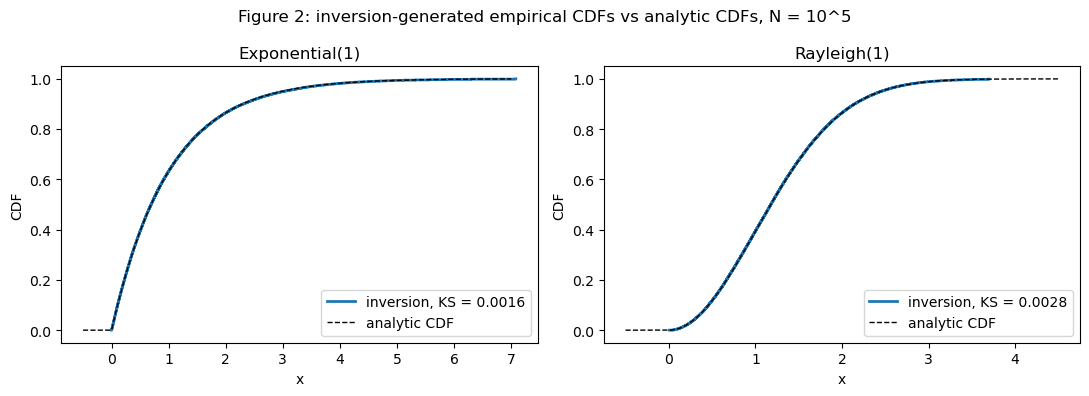

runtime so far: 1.5 s


In [11]:
# STEP 2 - Build Your Own Generator by Inversion

# Analytic CDFs
cdf_exp = lambda x: np.where(x > 0, 1 - np.exp(-np.maximum(x, 0)), 0.0)
cdf_ray = lambda x: np.where(x > 0, 1 - np.exp(-np.maximum(x, 0)**2 / 2), 0.0)
 
# Inversion samples and KS checks (analytic and library)
r2 = rng_step[2]
x_exp = sample_by_inversion(inv_cdf_exponential, N, r2, lam=1.0)
x_ray = sample_by_inversion(inv_cdf_rayleigh,    N, r2, sigma=1.0)
 
lib = np.random.default_rng(SEED + 1)
l_exp, l_ray = lib.exponential(1.0, N), lib.rayleigh(1.0, N)
 
ks_exp, ks_ray = ks_statistic(x_exp, cdf_exp), ks_statistic(x_ray, cdf_ray)
crit2 = 1.36 * np.sqrt(2 / N)
print(f"{'':<12}{'KS vs analytic':>16}{'crit':>8}{'KS vs library':>16}{'crit(2-sample)':>16}")
for name, x, l, ks in [("Exponential", x_exp, l_exp, ks_exp), ("Rayleigh", x_ray, l_ray, ks_ray)]:
    k2 = stats.ks_2samp(x, l).statistic
    print(f"{name:<12}{ks:>16.5f}{KS_CRIT:>8.4f}{k2:>16.5f}{crit2:>16.4f}")
 
print("\nmin of inversion samples:", x_exp.min(), x_ray.min(), "| any inf/nan:",
      not np.isfinite(np.concatenate([x_exp, x_ray])).all())
print("u=0 handled:", inv_cdf_exponential(0.0, 1.0), inv_cdf_rayleigh(0.0, 1.0))
 
# Figure 2: inversion CDFs vs analytic CDFs
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, x, cdf, ks, name, xs in [(ax[0], x_exp, cdf_exp, ks_exp, "Exponential(1)", (-0.5, 7)),
                                (ax[1], x_ray, cdf_ray, ks_ray, "Rayleigh(1)", (-0.5, 4.5))]:
    s = np.sort(x); xx = np.linspace(*xs, 1000)
    a.step(s[::100], np.arange(1, N+1)[::100]/N, where="post", color="C0", lw=2, label=f"inversion, KS = {ks:.4f}")
    a.plot(xx, cdf(xx), "k--", lw=1, label="analytic CDF")
    a.set_title(name); a.set_xlabel("x"); a.set_ylabel("CDF"); a.legend(loc="lower right")
fig.suptitle("Figure 2: inversion-generated empirical CDFs vs analytic CDFs, N = 10^5")
fig.tight_layout(); plt.show()
print(f"runtime so far: {time.time()-T0:.1f} s")

Number of samples: 1000000

Total area under PDF: 1.0000000000006237


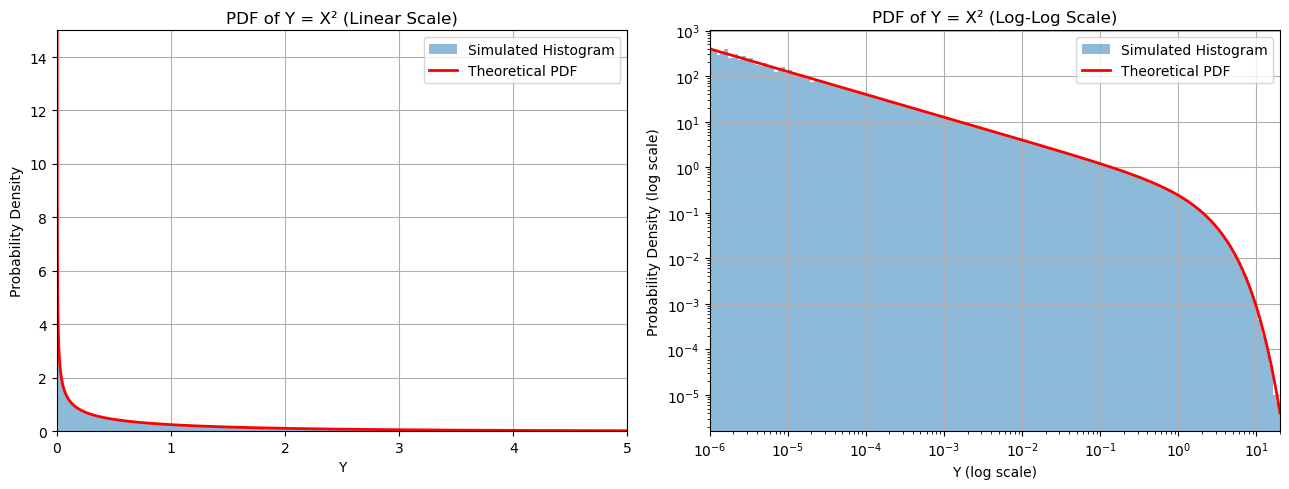


--- Probabilities and Median ---

P(Y <= 1)
Theoretical: 0.6826894921370859
Simulated: 0.682534

P(Y <= 0.1)
Theoretical: 0.24817036595415076
Simulated: 0.247918

Median of Y
Theoretical: 0.4549364231195727
Simulated: 0.4559814239558817

--- Mean and Variance ---

Mean
Theoretical: 1
Simulated: 1.0003786681880151

Variance
Theoretical: 2
Simulated: 1.9958888153560215

--- Final Observations ---
The PDF increases without bound as Y approaches 0.
However, the total area under the PDF is 1.
Log-spaced bins were used to show the divergence.
The slope on the log-log graph near zero is -0.5.
The simulated results agree with the theory.


In [12]:
# STEP 3: A FUNCTION OF A RANDOM VARIABLE

# 1. GENERATE RANDOM SAMPLES

np.random.seed(42)

N = 1_000_000

X = np.random.normal(0, 1, N)
Y = X**2

print("Number of samples:", len(Y))


# 2. VERIFY THAT PDF INTEGRATES TO 1


area, error = quad(
    lambda y: np.exp(-y / 2) / np.sqrt(2 * np.pi * y),
    0, np.inf
)

print("\nTotal area under PDF:", area)


# 3. FIGURE 3: HISTOGRAM AND PDF

# Log-spaced bins show the density near zero
bins = np.logspace(-6, np.log10(20), 160)
y_values = np.logspace(-6, np.log10(20), 1000)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graph 1: Linear scale
axes[0].hist(
    Y, bins=bins, density=True,
    alpha=0.5, label="Simulated Histogram"
)

axes[0].plot(
    y_values, pdf_y(y_values),
    'r-', linewidth=2, label="Theoretical PDF"
)

axes[0].set_xlim(0, 5)
axes[0].set_ylim(0, 15)
axes[0].set_title("PDF of Y = X² (Linear Scale)")
axes[0].set_xlabel("Y")
axes[0].set_ylabel("Probability Density")
axes[0].legend()
axes[0].grid(True)


# Graph 2: Log-log scale
axes[1].hist(
    Y, bins=bins, density=True,
    alpha=0.5, label="Simulated Histogram"
)

axes[1].plot(
    y_values, pdf_y(y_values),
    'r-', linewidth=2, label="Theoretical PDF"
)

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlim(1e-6, 20)
axes[1].set_title("PDF of Y = X² (Log-Log Scale)")
axes[1].set_xlabel("Y (log scale)")
axes[1].set_ylabel("Probability Density (log scale)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("Figure3.png", dpi=300)
plt.show()


# 4. PROBABILITIES AND MEDIAN
p1_theory = cdf_y(1)
p01_theory = cdf_y(0.1)
median_theory = norm.ppf(0.75)**2

p1_sim = np.mean(Y <= 1)
p01_sim = np.mean(Y <= 0.1)
median_sim = np.median(Y)

print("\n--- Probabilities and Median ---")

print("\nP(Y <= 1)")
print("Theoretical:", p1_theory)
print("Simulated:", p1_sim)

print("\nP(Y <= 0.1)")
print("Theoretical:", p01_theory)
print("Simulated:", p01_sim)

print("\nMedian of Y")
print("Theoretical:", median_theory)
print("Simulated:", median_sim)


# 5. MEAN AND VARIANCE
mean_theory = 1
variance_theory = 2

mean_sim = np.mean(Y)
variance_sim = np.var(Y)

print("\n--- Mean and Variance ---")

print("\nMean")
print("Theoretical:", mean_theory)
print("Simulated:", mean_sim)

print("\nVariance")
print("Theoretical:", variance_theory)
print("Simulated:", variance_sim)

# 6. FINAL OBSERVATIONS

print("\n--- Final Observations ---")

print("The PDF increases without bound as Y approaches 0.")
print("However, the total area under the PDF is 1.")
print("Log-spaced bins were used to show the divergence.")
print("The slope on the log-log graph near zero is -0.5.")
print("The simulated results agree with the theory.")


In [ ]:

# STEP 4: EXPECTATION AND MOMENTS



# Random seed
seed = 42
N = 1000000

# -----------------------------------
# Question 1: Rayleigh Raw Moments
# -----------------------------------

print("QUESTION 1: RAYLEIGH RAW MOMENTS")

rayleigh, pareto = generate_samples(N, seed)

theoretical_moments = rayleigh_moments()

for k in range(1, 5):
    theoretical = theoretical_moments[k - 1]

    # Calculate the sample raw moment
    sample_moment = np.mean(rayleigh ** k)

    # Standard error of the sample raw moment
    moment_2k = (2 ** k) * gamma(1 + k)
    standard_error = np.sqrt(
        (moment_2k - theoretical ** 2) / N
    )

    difference = (sample_moment - theoretical) / standard_error

    print(f"Moment {k}:")
    print(f"  Theoretical = {theoretical:.4f}")
    print(f"  Sample = {sample_moment:.4f}")
    print(f"  Difference in SE = {difference:.4f}")
    print()


# -----------------------------------
# Question 2: Pareto Moments
# -----------------------------------

print("QUESTION 2: PARETO MOMENTS")
print("Pareto shape = 1.5, scale = 1")
print("Theoretical mean = 3")
print("Theoretical second moment = infinity")
print("Theoretical variance = infinity")
print()


# -----------------------------------
# Question 3: Running Statistics
# -----------------------------------

print("QUESTION 3: RUNNING STATISTICS")

sizes = np.array([1000, 10000, 100000, 1000000])

ray_mean, ray_var = running_stats(rayleigh, sizes)
par_mean, par_var = running_stats(pareto, sizes)

for i in range(len(sizes)):
    print(f"N = {sizes[i]}")

    print(f"  Rayleigh Mean = {ray_mean[i]:.4f}")
    print(f"  Rayleigh Variance = {ray_var[i]:.4f}")

    print(f"  Pareto Mean = {par_mean[i]:.4f}")
    print(f"  Pareto Variance = {par_var[i]:.4f}")
    print()


# -----------------------------------
# Figure 4: Running Mean and Variance
# -----------------------------------

# Use more sample sizes for smoother plots
plot_sizes = np.unique(
    np.logspace(3, 6, 200).astype(int)
)

ray_plot_mean, ray_plot_var = running_stats(
    rayleigh, plot_sizes
)

par_plot_mean, par_plot_var = running_stats(
    pareto, plot_sizes
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: Running Mean
axes[0].plot(
    plot_sizes, ray_plot_mean,
    label="Rayleigh"
)

axes[0].plot(
    plot_sizes, par_plot_mean,
    label="Pareto"
)

axes[0].axhline(
    np.sqrt(np.pi / 2),
    color="green",
    linestyle="--",
    label="Rayleigh Theoretical Mean"
)

axes[0].axhline(
    3,
    color="red",
    linestyle="--",
    label="Pareto Theoretical Mean"
)

axes[0].set_xscale("log")
axes[0].set_xlabel("Sample Size N")
axes[0].set_ylabel("Running Mean")
axes[0].set_title("Running Sample Mean")
axes[0].legend()
axes[0].grid(True)


# Panel 2: Running Variance
axes[1].plot(
    plot_sizes, ray_plot_var,
    label="Rayleigh"
)

axes[1].plot(
    plot_sizes, par_plot_var,
    label="Pareto"
)

axes[1].axhline(
    (4 - np.pi) / 2,
    color="green",
    linestyle="--",
    label="Rayleigh Theoretical Variance"
)

axes[1].set_xscale("log")
axes[1].set_xlabel("Sample Size N")
axes[1].set_ylabel("Sample Variance")
axes[1].set_title("Running Sample Variance")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("figure4.png", dpi=300)
plt.show()


# -----------------------------------
# Question 4: Observations
# -----------------------------------

print("QUESTION 4: OBSERVATIONS")
print(
    "The Pareto sample mean gradually approaches 3 as "
    "the sample size increases."
)
print(
    "However, the sample variance does not converge "
    "because the theoretical variance is infinite."
)
print(
    "Python can still calculate a sample variance "
    "because the generated sample contains a finite "
    "number of values."
)
print(
    "This variance represents the spread of the "
    "particular sample, not a stable estimate "
    "of the population variance."
)
print()


# -----------------------------------
# Question 5: Practical Rule
# -----------------------------------

print("QUESTION 5: PRACTICAL RULE")
print(
    "Before reporting error bars, we should check "
    "whether the data has a finite variance."
)
print(
    "If the variance is infinite, traditional error "
    "bars based on sample standard deviation may "
    "be misleading."
)
